# **PROJETO STP - M5 Forescasting**

### **Projeto desenvolvido por:**
- João Vasques, nº2250055
- Rui Filipe Parada, nº2211025

---

# **Phase 2 - Machine Learning Models**

## **1. Imports and Data Upload**

In [1]:
!pip install mlforecast

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.1/128.1 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.2/348.2 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 43.4 MB/s eta 0:00:00


In [67]:
# Imports principais
from google.colab import files
import pandas as pd
import numpy as np
import io
import operator

# Visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
from utilsforecast.plotting import plot_series

# Estatística e métricas de avaliação
from scipy import stats
import sklearn.metrics as metrics

# Forecasting (Framework mlforecast)
from mlforecast import MLForecast
from mlforecast.utils import generate_daily_series, PredictionIntervals
from mlforecast.target_transforms import Differences, LocalStandardScaler
from mlforecast.lag_transforms import RollingMean, ExpandingMean, Combine, Offset

# Modelos Regressores (Machine Learning)
import lightgbm as lgb
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.base import BaseEstimator

Começamos por carregar os ficheiros CSV com as séries temporais do departamento selecionado e o ficheiro dos resultados obtidos pelos Baseline Models, AutoARIMA e AutoETS. Este ficheiro será utilizado posteriormente para comparar o desempenho dos modelos de Machine Learning desenvolvidos nesta fase.

In [3]:
# Carregar o ficheiro com os dados do departamento escolhido e dos resultados dos BaselineModels, AutoArima e AutoETS

uploaded = files.upload()

if 'HOBBIES_2_TX1.csv' in uploaded and 'Results_AutoETS.csv' in uploaded:
    Y_df_HOBBIES_2_TX1 = pd.read_csv(io.BytesIO(uploaded['HOBBIES_2_TX1.csv']), parse_dates=['ds'])
    Results_AutoETS = pd.read_csv(io.BytesIO(uploaded['Results_AutoETS.csv']), sep=',')
    print("Both files uploaded successfully.")
else:
    print("Please ensure both 'HOBBIES_2_TX1.csv' and 'Results_AutoETS.csv' are uploaded.")

Y_df_HOBBIES_2_TX1

Saving HOBBIES_2_TX1.csv to HOBBIES_2_TX1.csv
Saving Results_AutoETS.csv to Results_AutoETS.csv
Both files uploaded successfully.


,unique_id,ds,y
0,HOBBIES_2_001_TX_1,2011-02-11,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
221726,HOBBIES_2_149_TX_1,2016-06-15,0.0
221727,HOBBIES_2_149_TX_1,2016-06-16,0.0
221728,HOBBIES_2_149_TX_1,2016-06-17,0.0
221729,HOBBIES_2_149_TX_1,2016-06-18,2.0


## **2. Data Preparation and Splitting**

### **2.1. Estruturação da Univariate Time Series**

In [4]:
train = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] <= '2016-05-22'] #Selecionar os dados anteriores aos últimos 28 dias de cada série
train

,unique_id,ds,y
0,HOBBIES_2_001_TX_1,2011-02-11,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,0.0
...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0


In [5]:
test = Y_df_HOBBIES_2_TX1[Y_df_HOBBIES_2_TX1['ds'] > '2016-05-22'] #Selecionar os últimos 28 dias de cada série
test

,unique_id,ds,y
1928,HOBBIES_2_001_TX_1,2016-05-23,0.0
1929,HOBBIES_2_001_TX_1,2016-05-24,0.0
1930,HOBBIES_2_001_TX_1,2016-05-25,0.0
1931,HOBBIES_2_001_TX_1,2016-05-26,0.0
1932,HOBBIES_2_001_TX_1,2016-05-27,0.0
...,...,...,...
221726,HOBBIES_2_149_TX_1,2016-06-15,0.0
221727,HOBBIES_2_149_TX_1,2016-06-16,0.0
221728,HOBBIES_2_149_TX_1,2016-06-17,0.0
221729,HOBBIES_2_149_TX_1,2016-06-18,2.0


In [6]:
train.shape, test.shape

((217559, 3), (4172, 3))

### **2.2. Estruturação de Exogenous Regressors e Covariáveis**

In [7]:
base_url = 'https://datasets-nixtla.s3.amazonaws.com'

X_df = pd.read_parquet(f'{base_url}/m5_x.parquet')

In [8]:
X_df_HOBBIES2 = X_df[X_df['unique_id'].str.startswith('HOBBIES_2')]
X_df_HOBBIES2_TX1 = X_df_HOBBIES2[X_df_HOBBIES2['unique_id'].str.endswith('TX_1')]
X_df_HOBBIES2_TX1

,unique_id,ds,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,sell_price
28860162,HOBBIES_2_001_TX_1,2011-02-11,nan,nan,nan,nan,0,1,1,5.47
28860163,HOBBIES_2_001_TX_1,2011-02-12,nan,nan,nan,nan,0,1,1,5.47
28860164,HOBBIES_2_001_TX_1,2011-02-13,nan,nan,nan,nan,0,1,0,5.47
28860165,HOBBIES_2_001_TX_1,2011-02-14,ValentinesDay,Cultural,nan,nan,0,0,1,5.47
28860166,HOBBIES_2_001_TX_1,2011-02-15,nan,nan,nan,nan,0,1,1,5.47
...,...,...,...,...,...,...,...,...,...,...
31097066,HOBBIES_2_149_TX_1,2016-06-15,nan,nan,nan,nan,0,1,1,0.97
31097067,HOBBIES_2_149_TX_1,2016-06-16,nan,nan,nan,nan,0,0,0,0.97
31097068,HOBBIES_2_149_TX_1,2016-06-17,nan,nan,nan,nan,0,0,0,0.97
31097069,HOBBIES_2_149_TX_1,2016-06-18,nan,nan,nan,nan,0,0,0,0.97


In [9]:
regressors_train = X_df_HOBBIES2_TX1[X_df_HOBBIES2_TX1['ds'] <= '2016-05-22']
regressors_test = X_df_HOBBIES2_TX1[X_df_HOBBIES2_TX1['ds'] > '2016-05-22']

In [10]:
regressors_train = regressors_train[['unique_id', 'ds', 'sell_price', 'snap_TX']]
regressors_train

,unique_id,ds,sell_price,snap_TX
28860162,HOBBIES_2_001_TX_1,2011-02-11,5.47,1
28860163,HOBBIES_2_001_TX_1,2011-02-12,5.47,1
28860164,HOBBIES_2_001_TX_1,2011-02-13,5.47,1
28860165,HOBBIES_2_001_TX_1,2011-02-14,5.47,0
28860166,HOBBIES_2_001_TX_1,2011-02-15,5.47,1
...,...,...,...,...
31097038,HOBBIES_2_149_TX_1,2016-05-18,0.97,0
31097039,HOBBIES_2_149_TX_1,2016-05-19,0.97,0
31097040,HOBBIES_2_149_TX_1,2016-05-20,0.97,0
31097041,HOBBIES_2_149_TX_1,2016-05-21,0.97,0


In [11]:
regressors_test = regressors_test[['unique_id', 'ds', 'sell_price', 'snap_TX']]
regressors_test

,unique_id,ds,sell_price,snap_TX
28862090,HOBBIES_2_001_TX_1,2016-05-23,5.47,0
28862091,HOBBIES_2_001_TX_1,2016-05-24,5.47,0
28862092,HOBBIES_2_001_TX_1,2016-05-25,5.47,0
28862093,HOBBIES_2_001_TX_1,2016-05-26,5.47,0
28862094,HOBBIES_2_001_TX_1,2016-05-27,5.47,0
...,...,...,...,...
31097066,HOBBIES_2_149_TX_1,2016-06-15,0.97,1
31097067,HOBBIES_2_149_TX_1,2016-06-16,0.97,0
31097068,HOBBIES_2_149_TX_1,2016-06-17,0.97,0
31097069,HOBBIES_2_149_TX_1,2016-06-18,0.97,0


In [12]:
regressors_train.shape, regressors_test.shape

((217559, 4), (4172, 4))

In [13]:
regressors_train = regressors_train.merge(train[['unique_id', 'ds', 'y']],on=['unique_id', 'ds'],how='left')
regressors_train

,unique_id,ds,sell_price,snap_TX,y
0,HOBBIES_2_001_TX_1,2011-02-11,5.47,1,1.0
1,HOBBIES_2_001_TX_1,2011-02-12,5.47,1,0.0
2,HOBBIES_2_001_TX_1,2011-02-13,5.47,1,0.0
3,HOBBIES_2_001_TX_1,2011-02-14,5.47,0,0.0
4,HOBBIES_2_001_TX_1,2011-02-15,5.47,1,0.0
...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0


## **3. Modeling**

Os modelos abordados em aula e selecionados para esta fase são o KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge e LightGBMRegressor. Os modelos selecionados para esta fase de machine learning são instanciados em conjunto, de forma a simplificar a leitura do código.

In [14]:
models = [
    KNeighborsRegressor(),
    Lasso(),
    LinearRegression(),
    MLPRegressor(),
    Ridge(),
    lgb.LGBMRegressor(),

]

In [15]:
freq = "D"
season_length = 7
horizon = 28
levels = [95]

### **3.1. Definição de cenários e configurações**

Os doze cenários definidos resultam da combinação sistemática de três dimensões alteráveis do pipeline: a aplicação ou não de target transformations (Differences), a utilização de diferentes conjuntos de lags
[
1
,
7
]
,
[
1
,
7
,
14
,
21
]
,
[
1
,
7
,
14
,
21
,
28
]
 e a inclusão ou ausência de covariáveis externas. Para garantir consistência entre cenários, mantêm‑se fixas as lag transformations (ExpandingMean e RollingMean) e as date features utilizadas (day of week e month).

Os cenários 1 a 6 correspondem às configurações sem covariáveis, variando apenas as transformações do target e o conjunto de lags. Os cenários 7 a 12 replicam exatamente estas combinações, mas incluindo covariáveis externas, alinhadas com as utilizadas no AutoARIMA na fase anterior.

In [16]:
"""
APLICAR CENÁRIOS 1 A 6 A TRAIN E TEST

"""

### ---------- CENÁRIO 1 ---------- ###

# Traget Transformations -> sem
# Lags -> [1, 7]
# Covariáveis -> sem

fcst_1 = MLForecast(
    models=models,
    freq=freq,
    lags = [1, 7],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 2 ---------- ###

# Traget Transformations -> sem
# Lags -> [1, 7, 14, 21]
# Covariáveis -> sem

fcst_2 = MLForecast(
    models=models,
    freq=freq,
    lags = [1, 7, 14, 21],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 3 ---------- ###

# Traget Transformations -> sem
# Lags -> [1, 7, 14, 21, 28]
# Covariáveis -> sem

fcst_3 = MLForecast(
    models=models,
    freq=freq,
    lags = [1, 7, 14, 21, 28],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 4 ---------- ###

# Traget Transformations -> com
# Lags -> [1, 7]
# Covariáveis -> sem

fcst_4 = MLForecast(
    models=models,
    freq=freq,
    target_transforms=[Differences([7])],
    lags = [1, 7],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 5 ---------- ###

# Traget Transformations -> com
# Lags -> [1, 7, 14, 21]
# Covariáveis -> sem

fcst_5 = MLForecast(
    models=models,
    freq=freq,
    target_transforms=[Differences([7])],
    lags = [1, 7, 14, 21],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 6 ---------- ###

# Traget Transformations -> com
# Lags -> [1, 7, 14, 21, 28]
# Covariáveis -> sem

fcst_6 = MLForecast(
    models=models,
    freq=freq,
    target_transforms=[Differences([7])],
    lags = [1, 7, 14, 21, 28],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)

In [17]:
"""
APLICAR CENÁRIOS 7 A 12 A REGRESSORS_TRAIN E REGRESSORS_TEST

"""

### ---------- CENÁRIO 7 ---------- ###

# Traget Transformations -> sem
# Lags -> [1, 7]
# Covariáveis -> com

fcst_7 = MLForecast(
    models=models,
    freq=freq,
    lags = [1, 7],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 8 ---------- ###

# Traget Transformations -> sem
# Lags -> [1, 7, 14, 21]
# Covariáveis -> com

fcst_8 = MLForecast(
    models=models,
    freq=freq,
    lags = [1, 7, 14, 21],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 9 ---------- ###

# Traget Transformations -> sem
# Lags -> [1, 7, 14, 21, 28]
# Covariáveis -> com

fcst_9 = MLForecast(
    models=models,
    freq=freq,
    lags = [1, 7, 14, 21, 28],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 10 ---------- ###

# Traget Transformations -> com
# Lags -> [1, 7]
# Covariáveis -> com

fcst_10 = MLForecast(
    models=models,
    freq=freq,
    target_transforms=[Differences([7])],
    lags = [1, 7],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 11 ---------- ###

# Traget Transformations -> com
# Lags -> [1, 7, 14, 21]
# Covariáveis -> com

fcst_11 = MLForecast(
    models=models,
    freq=freq,
    target_transforms=[Differences([7])],
    lags = [1, 7, 14, 21],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)



### ---------- CENÁRIO 12 ---------- ###

# Traget Transformations -> com
# Lags -> [1, 7, 14, 21, 28]
# Covariáveis -> com

fcst_12 = MLForecast(
    models=models,
    freq=freq,
    target_transforms=[Differences([7])],
    lags = [1, 7, 14, 21, 28],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],},
    date_features=['dayofweek', 'month']
)

### **3.2. Preprocessing**

In [18]:
fcst_1.preprocess(train)

,unique_id,ds,y,lag1,lag7,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,0.299910,0.392857,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,0.0,0.302347,0.357143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.302074,0.357143,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.301802,0.321429,5,5


In [19]:
fcst_2.preprocess(train)

,unique_id,ds,y,lag1,lag7,lag14,lag21,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,0.0,0.0,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,0.0,0.0,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,0.0,0.0,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,0.0,0.0,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,0.0,0.0,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,0.0,1.0,0.299910,0.392857,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,0.0,1.0,1.0,0.302347,0.357143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.0,0.0,0.302074,0.357143,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.0,0.0,0.301802,0.321429,5,5


In [20]:
fcst_3.preprocess(train)

,unique_id,ds,y,lag1,lag7,lag14,lag21,lag28,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,0.0,0.0,0.0,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,0.0,0.0,0.0,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,0.0,0.0,0.0,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,0.0,0.0,0.0,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,0.0,0.0,0.0,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,0.0,1.0,0.0,0.299910,0.392857,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,0.0,1.0,1.0,0.0,0.302347,0.357143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.0,0.0,0.0,0.302074,0.357143,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.0,0.0,0.0,0.301802,0.321429,5,5


In [21]:
fcst_4.preprocess(train)

,unique_id,ds,y,lag1,lag7,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
41,HOBBIES_2_001_TX_1,2011-03-24,0.0,0.0,0.0,-0.029412,0.000000,3,3
42,HOBBIES_2_001_TX_1,2011-03-25,0.0,0.0,0.0,-0.028571,0.035714,4,3
43,HOBBIES_2_001_TX_1,2011-03-26,0.0,0.0,0.0,-0.027778,0.035714,5,3
44,HOBBIES_2_001_TX_1,2011-03-27,0.0,0.0,0.0,-0.027027,0.035714,6,3
45,HOBBIES_2_001_TX_1,2011-03-28,0.0,0.0,0.0,-0.026316,0.035714,0,3
...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,0.000000,-0.035714,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,-1.0,0.002725,-0.107143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.002722,-0.071429,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.002720,-0.107143,5,5


In [22]:
fcst_5.preprocess(train)

,unique_id,ds,y,lag1,lag7,lag14,lag21,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
41,HOBBIES_2_001_TX_1,2011-03-24,0.0,0.0,0.0,0.0,0.0,-0.029412,0.000000,3,3
42,HOBBIES_2_001_TX_1,2011-03-25,0.0,0.0,0.0,0.0,0.0,-0.028571,0.035714,4,3
43,HOBBIES_2_001_TX_1,2011-03-26,0.0,0.0,0.0,0.0,0.0,-0.027778,0.035714,5,3
44,HOBBIES_2_001_TX_1,2011-03-27,0.0,0.0,0.0,0.0,0.0,-0.027027,0.035714,6,3
45,HOBBIES_2_001_TX_1,2011-03-28,0.0,0.0,0.0,0.0,0.0,-0.026316,0.035714,0,3
...,...,...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,-1.0,1.0,0.000000,-0.035714,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,-1.0,0.0,1.0,0.002725,-0.107143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.0,0.0,0.002722,-0.071429,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.0,0.0,0.002720,-0.107143,5,5


In [23]:
fcst_6.preprocess(train)

,unique_id,ds,y,lag1,lag7,lag14,lag21,lag28,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
41,HOBBIES_2_001_TX_1,2011-03-24,0.0,0.0,0.0,0.0,0.0,0.0,-0.029412,0.000000,3,3
42,HOBBIES_2_001_TX_1,2011-03-25,0.0,0.0,0.0,0.0,0.0,0.0,-0.028571,0.035714,4,3
43,HOBBIES_2_001_TX_1,2011-03-26,0.0,0.0,0.0,0.0,0.0,0.0,-0.027778,0.035714,5,3
44,HOBBIES_2_001_TX_1,2011-03-27,0.0,0.0,0.0,0.0,0.0,0.0,-0.027027,0.035714,6,3
45,HOBBIES_2_001_TX_1,2011-03-28,0.0,0.0,0.0,0.0,0.0,0.0,-0.026316,0.035714,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,-1.0,1.0,-1.0,0.000000,-0.035714,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,-1.0,0.0,1.0,-1.0,0.002725,-0.107143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.0,0.0,0.0,0.002722,-0.071429,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.0,0.0,-1.0,0.002720,-0.107143,5,5


In [24]:
fcst_7.preprocess(regressors_train, static_features=[])

,unique_id,ds,sell_price,snap_TX,y,lag1,lag7,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,5.47,0,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,5.47,0,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,5.47,0,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,5.47,0,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,5.47,0,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0,1.0,0.0,0.299910,0.392857,2,5
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0,3.0,0.0,0.302347,0.357143,3,5
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0,0.0,0.0,0.302074,0.357143,4,5
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0,0.0,0.0,0.301802,0.321429,5,5


In [25]:
fcst_8.preprocess(regressors_train, static_features=[])

,unique_id,ds,sell_price,snap_TX,y,lag1,lag7,lag14,lag21,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,5.47,0,0.0,0.0,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,5.47,0,0.0,0.0,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,5.47,0,0.0,0.0,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,5.47,0,0.0,0.0,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,5.47,0,0.0,0.0,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0,1.0,0.0,0.0,1.0,0.299910,0.392857,2,5
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0,3.0,0.0,1.0,1.0,0.302347,0.357143,3,5
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0,0.0,0.0,0.0,0.0,0.302074,0.357143,4,5
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0,0.0,0.0,0.0,0.0,0.301802,0.321429,5,5


In [26]:
fcst_9.preprocess(regressors_train, static_features=[])

,unique_id,ds,sell_price,snap_TX,y,lag1,lag7,lag14,lag21,lag28,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0,1.0,0.0,0.0,1.0,0.0,0.299910,0.392857,2,5
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0,3.0,0.0,1.0,1.0,0.0,0.302347,0.357143,3,5
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0,0.0,0.0,0.0,0.0,0.0,0.302074,0.357143,4,5
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0,0.0,0.0,0.0,0.0,0.0,0.301802,0.321429,5,5


In [27]:
fcst_10.preprocess(regressors_train, static_features=[])

,unique_id,ds,sell_price,snap_TX,y,lag1,lag7,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
41,HOBBIES_2_001_TX_1,2011-03-24,5.47,0,0.0,0.0,0.0,-0.029412,0.000000,3,3
42,HOBBIES_2_001_TX_1,2011-03-25,5.47,0,0.0,0.0,0.0,-0.028571,0.035714,4,3
43,HOBBIES_2_001_TX_1,2011-03-26,5.47,0,0.0,0.0,0.0,-0.027778,0.035714,5,3
44,HOBBIES_2_001_TX_1,2011-03-27,5.47,0,0.0,0.0,0.0,-0.027027,0.035714,6,3
45,HOBBIES_2_001_TX_1,2011-03-28,5.47,0,0.0,0.0,0.0,-0.026316,0.035714,0,3
...,...,...,...,...,...,...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0,1.0,0.0,0.000000,-0.035714,2,5
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0,3.0,-1.0,0.002725,-0.107143,3,5
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0,0.0,0.0,0.002722,-0.071429,4,5
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0,0.0,0.0,0.002720,-0.107143,5,5


In [28]:
fcst_11.preprocess(regressors_train, static_features=[])

,unique_id,ds,sell_price,snap_TX,y,lag1,lag7,lag14,lag21,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
41,HOBBIES_2_001_TX_1,2011-03-24,5.47,0,0.0,0.0,0.0,0.0,0.0,-0.029412,0.000000,3,3
42,HOBBIES_2_001_TX_1,2011-03-25,5.47,0,0.0,0.0,0.0,0.0,0.0,-0.028571,0.035714,4,3
43,HOBBIES_2_001_TX_1,2011-03-26,5.47,0,0.0,0.0,0.0,0.0,0.0,-0.027778,0.035714,5,3
44,HOBBIES_2_001_TX_1,2011-03-27,5.47,0,0.0,0.0,0.0,0.0,0.0,-0.027027,0.035714,6,3
45,HOBBIES_2_001_TX_1,2011-03-28,5.47,0,0.0,0.0,0.0,0.0,0.0,-0.026316,0.035714,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0,1.0,0.0,-1.0,1.0,0.000000,-0.035714,2,5
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0,3.0,-1.0,0.0,1.0,0.002725,-0.107143,3,5
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0,0.0,0.0,0.0,0.0,0.002722,-0.071429,4,5
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0,0.0,0.0,0.0,0.0,0.002720,-0.107143,5,5


In [29]:
fcst_12.preprocess(regressors_train, static_features=[])

,unique_id,ds,sell_price,snap_TX,y,lag1,lag7,lag14,lag21,lag28,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
41,HOBBIES_2_001_TX_1,2011-03-24,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.029412,0.000000,3,3
42,HOBBIES_2_001_TX_1,2011-03-25,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.028571,0.035714,4,3
43,HOBBIES_2_001_TX_1,2011-03-26,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.027778,0.035714,5,3
44,HOBBIES_2_001_TX_1,2011-03-27,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.027027,0.035714,6,3
45,HOBBIES_2_001_TX_1,2011-03-28,5.47,0,0.0,0.0,0.0,0.0,0.0,0.0,-0.026316,0.035714,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
217554,HOBBIES_2_149_TX_1,2016-05-18,0.97,0,3.0,1.0,0.0,-1.0,1.0,-1.0,0.000000,-0.035714,2,5
217555,HOBBIES_2_149_TX_1,2016-05-19,0.97,0,0.0,3.0,-1.0,0.0,1.0,-1.0,0.002725,-0.107143,3,5
217556,HOBBIES_2_149_TX_1,2016-05-20,0.97,0,0.0,0.0,0.0,0.0,0.0,0.0,0.002722,-0.071429,4,5
217557,HOBBIES_2_149_TX_1,2016-05-21,0.97,0,1.0,0.0,0.0,0.0,0.0,-1.0,0.002720,-0.107143,5,5


### **3.3. Fit dos modelos**

In [30]:
fcst_1.fit(train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009053 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 444
[LightGBM] [Info] Number of data points in the train set: 212493, number of used features: 6
[LightGBM] [Info] Start training from score 0.203381


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [31]:
fcst_2.fit(train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012717 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 492
[LightGBM] [Info] Number of data points in the train set: 212493, number of used features: 8
[LightGBM] [Info] Start training from score 0.203381


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [32]:
fcst_3.fit(train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016525 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 515
[LightGBM] [Info] Number of data points in the train set: 212493, number of used features: 9
[LightGBM] [Info] Start training from score 0.203381


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'lag28', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [33]:
fcst_4.fit(train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010765 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 446
[LightGBM] [Info] Number of data points in the train set: 211450, number of used features: 6
[LightGBM] [Info] Start training from score 0.000813


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [34]:
fcst_5.fit(train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.023895 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 532
[LightGBM] [Info] Number of data points in the train set: 211450, number of used features: 8
[LightGBM] [Info] Start training from score 0.000813


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [35]:
fcst_6.fit(train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018105 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 575
[LightGBM] [Info] Number of data points in the train set: 211450, number of used features: 9
[LightGBM] [Info] Start training from score 0.000813


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'lag28', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [36]:
fcst_7.fit(regressors_train, static_features=[])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012157 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 506
[LightGBM] [Info] Number of data points in the train set: 212493, number of used features: 8
[LightGBM] [Info] Start training from score 0.203381


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [37]:
fcst_8.fit(regressors_train, static_features=[])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024583 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 554
[LightGBM] [Info] Number of data points in the train set: 212493, number of used features: 10
[LightGBM] [Info] Start training from score 0.203381


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [38]:
fcst_9.fit(regressors_train, static_features=[])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021227 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 577
[LightGBM] [Info] Number of data points in the train set: 212493, number of used features: 11
[LightGBM] [Info] Start training from score 0.203381


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'lag28', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [39]:
fcst_10.fit(regressors_train, static_features=[])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016587 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 508
[LightGBM] [Info] Number of data points in the train set: 211450, number of used features: 8
[LightGBM] [Info] Start training from score 0.000813


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [40]:
fcst_11.fit(regressors_train, static_features=[])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.019677 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 594
[LightGBM] [Info] Number of data points in the train set: 211450, number of used features: 10
[LightGBM] [Info] Start training from score 0.000813


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [41]:
fcst_12.fit(regressors_train, static_features=[])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.021944 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 637
[LightGBM] [Info] Number of data points in the train set: 211450, number of used features: 11
[LightGBM] [Info] Start training from score 0.000813


MLForecast(models=[KNeighborsRegressor, Lasso, LinearRegression, MLPRegressor, Ridge, LGBMRegressor], freq=D, lag_features=['lag1', 'lag7', 'lag14', 'lag21', 'lag28', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

### **3.4. Forecasts**

In [42]:
forecasts_1 = fcst_1.predict(h=horizon)
forecasts_1

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.203381,0.029206,0.032304,0.029212,0.059423
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.203381,0.036724,0.060975,0.036730,0.126805
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.203381,0.042294,0.045895,0.042301,0.126805
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.203381,0.047690,0.045387,0.047697,0.126805
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.203381,0.053071,0.050612,0.053078,0.126509
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.6,0.203381,0.401347,0.433429,0.401335,0.460365
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,0.203381,0.413849,0.451349,0.413837,0.481620
4169,HOBBIES_2_149_TX_1,2016-06-17,0.2,0.203381,0.427254,0.478305,0.427241,0.446403
4170,HOBBIES_2_149_TX_1,2016-06-18,0.0,0.203381,0.441088,0.490924,0.441075,0.493913


In [43]:
forecasts_2 = fcst_2.predict(h=horizon)
forecasts_2

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.203381,0.028953,0.045226,0.028959,0.058710
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.203381,0.036390,0.056992,0.036396,0.137340
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.203381,0.041896,0.057902,0.041902,0.137340
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.203381,0.047229,0.064808,0.047235,0.137340
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.203381,0.052548,0.073142,0.052554,0.134127
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.0,0.203381,0.401155,0.397435,0.401144,0.455764
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,0.203381,0.412229,0.407704,0.412216,0.469591
4169,HOBBIES_2_149_TX_1,2016-06-17,0.6,0.203381,0.425177,0.428684,0.425163,0.473895
4170,HOBBIES_2_149_TX_1,2016-06-18,0.6,0.203381,0.439451,0.429800,0.439437,0.500089


In [44]:
forecasts_3 = fcst_3.predict(h=horizon)
forecasts_3

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.203381,0.029084,0.074812,0.029090,0.059286
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.203381,0.036562,0.069889,0.036568,0.130507
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.203381,0.042101,0.065290,0.042107,0.130507
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.203381,0.047467,0.073450,0.047473,0.130507
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.203381,0.052818,0.075654,0.052824,0.128392
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.0,0.203381,0.387008,0.449837,0.387013,0.453804
4168,HOBBIES_2_149_TX_1,2016-06-16,0.2,0.203381,0.413841,0.463949,0.413825,0.470132
4169,HOBBIES_2_149_TX_1,2016-06-17,0.2,0.203381,0.428439,0.464471,0.428421,0.455488
4170,HOBBIES_2_149_TX_1,2016-06-18,0.0,0.203381,0.437493,0.452057,0.437481,0.482641


In [45]:
forecasts_4 = fcst_4.predict(h=horizon)
forecasts_4

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,4.000000e-01,0.000813,-0.003676,0.092209,-0.003533,0.080745
1,HOBBIES_2_001_TX_1,2016-05-24,0.000000e+00,0.000813,-0.003855,0.096812,-0.003709,0.194569
2,HOBBIES_2_001_TX_1,2016-05-25,0.000000e+00,0.000813,-0.003963,0.082699,-0.003817,0.194569
3,HOBBIES_2_001_TX_1,2016-05-26,2.000000e-01,0.000813,-0.004069,0.079185,-0.003923,0.194569
4,HOBBIES_2_001_TX_1,2016-05-27,0.000000e+00,0.000813,-0.004174,0.083913,-0.004030,0.188032
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,8.000000e-01,3.003254,1.865191,0.719540,1.865630,0.251968
4168,HOBBIES_2_149_TX_1,2016-06-16,8.000000e-01,0.003254,-0.255990,0.391620,-0.255525,-1.009213
4169,HOBBIES_2_149_TX_1,2016-06-17,2.000000e-01,0.003254,-0.243159,0.406559,-0.242732,-1.022440
4170,HOBBIES_2_149_TX_1,2016-06-18,4.000000e-01,1.003254,0.428882,0.566327,0.429279,0.124385


In [46]:
forecasts_5 = fcst_5.predict(h=horizon)
forecasts_5

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.4,0.000813,0.000070,0.080025,0.000126,0.071412
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.000813,0.000003,0.088376,0.000061,0.176983
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.000813,-0.000067,0.091463,-0.000010,0.176983
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.000813,-0.000137,0.090492,-0.000080,0.176983
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.000813,-0.000208,0.087962,-0.000150,0.175316
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,1.8,3.003254,1.536406,0.739679,1.536531,0.670681
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,0.003254,0.197452,0.286844,0.197594,-0.861768
4169,HOBBIES_2_149_TX_1,2016-06-17,-0.2,0.003254,-0.051237,0.229458,-0.051107,-1.004402
4170,HOBBIES_2_149_TX_1,2016-06-18,0.6,1.003254,0.433471,0.404674,0.433595,0.202128


In [47]:
forecasts_6 = fcst_6.predict(h=horizon)
forecasts_6

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.4,0.000813,0.000652,0.076157,0.000697,0.071696
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.000813,0.000594,0.071871,0.000641,0.185851
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.000813,0.000513,0.065933,0.000559,0.185851
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.000813,0.000430,0.061788,0.000476,0.185851
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.000813,0.000347,0.057800,0.000393,0.184462
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.8,3.003254,1.154261,0.665389,1.154356,0.738735
4168,HOBBIES_2_149_TX_1,2016-06-16,0.4,0.003254,0.268024,0.340402,0.268094,-0.857964
4169,HOBBIES_2_149_TX_1,2016-06-17,0.2,0.003254,0.031054,0.210343,0.031115,-1.010818
4170,HOBBIES_2_149_TX_1,2016-06-18,0.6,1.003254,0.378605,0.419164,0.378666,0.133063


In [48]:
forecasts_7 = fcst_7.predict(h=horizon, X_df=regressors_test)
forecasts_7

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.203381,0.015394,0.098254,0.015398,0.059525
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.203381,0.021658,0.103581,0.021663,0.118067
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.203381,0.027106,0.089131,0.027110,0.118067
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.203381,0.032480,0.072852,0.032485,0.118067
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.203381,0.037849,0.066445,0.037854,0.115013
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.0,0.203381,0.415286,0.434445,0.415277,0.460382
4168,HOBBIES_2_149_TX_1,2016-06-16,0.4,0.203381,0.425009,0.424687,0.424999,0.463719
4169,HOBBIES_2_149_TX_1,2016-06-17,0.2,0.203381,0.438183,0.423619,0.438172,0.405878
4170,HOBBIES_2_149_TX_1,2016-06-18,0.8,0.203381,0.452315,0.422132,0.452304,0.495614


In [49]:
forecasts_8 = fcst_8.predict(h=horizon, X_df=regressors_test)
forecasts_8

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.203381,0.015143,0.079993,0.015148,0.055306
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.203381,0.021328,0.083893,0.021333,0.122745
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.203381,0.026711,0.080334,0.026716,0.122745
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.203381,0.032023,0.089679,0.032027,0.122745
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.203381,0.037329,0.103662,0.037333,0.122303
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.4,0.203381,0.415141,0.415567,0.415132,0.461822
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,0.203381,0.423425,0.399910,0.423414,0.485220
4169,HOBBIES_2_149_TX_1,2016-06-17,0.2,0.203381,0.436161,0.412559,0.436148,0.471852
4170,HOBBIES_2_149_TX_1,2016-06-18,0.8,0.203381,0.450706,0.452279,0.450693,0.553311


In [50]:
forecasts_9 = fcst_9.predict(h=horizon, X_df=regressors_test)
forecasts_9

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.203381,0.015280,0.102235,0.015284,0.055395
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.203381,0.021507,0.106885,0.021511,0.121142
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.203381,0.026923,0.099591,0.026927,0.121142
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.203381,0.032267,0.088290,0.032272,0.121142
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.203381,0.037606,0.077421,0.037610,0.119032
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.0,0.203381,0.401048,0.421355,0.401055,0.473843
4168,HOBBIES_2_149_TX_1,2016-06-16,0.0,0.203381,0.425069,0.504864,0.425055,0.490355
4169,HOBBIES_2_149_TX_1,2016-06-17,0.4,0.203381,0.439452,0.509485,0.439435,0.473580
4170,HOBBIES_2_149_TX_1,2016-06-18,0.4,0.203381,0.448792,0.475538,0.448781,0.557341


In [51]:
forecasts_10 = fcst_10.predict(h=horizon, X_df=regressors_test)
forecasts_10

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.000813,-0.005607,0.077753,-0.005499,0.066489
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.000813,-0.005836,0.082105,-0.005726,0.163703
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.000813,-0.005955,0.089915,-0.005845,0.163703
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.000813,-0.006072,0.098045,-0.005963,0.163703
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.000813,-0.006189,0.106210,-0.006080,0.162259
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,1.2,3.003254,1.870239,0.592527,1.870732,0.232056
4168,HOBBIES_2_149_TX_1,2016-06-16,0.6,0.003254,-0.259031,0.414963,-0.258517,-0.895354
4169,HOBBIES_2_149_TX_1,2016-06-17,0.0,0.003254,-0.244889,0.393330,-0.244412,-0.899527
4170,HOBBIES_2_149_TX_1,2016-06-18,0.4,1.003254,0.425666,0.557837,0.426111,0.201240


In [52]:
forecasts_11 = fcst_11.predict(h=horizon, X_df=regressors_test)
forecasts_11

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.000813,-0.001841,0.092057,-0.001799,0.049746
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.000813,-0.001962,0.071942,-0.001919,0.145106
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.000813,-0.002039,0.078597,-0.001996,0.145106
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.000813,-0.002114,0.088813,-0.002071,0.145106
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.000813,-0.002190,0.099237,-0.002147,0.143761
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,1.0,3.003254,1.539511,0.689353,1.539652,0.685493
4168,HOBBIES_2_149_TX_1,2016-06-16,0.4,0.003254,0.197408,0.430956,0.197567,-0.795002
4169,HOBBIES_2_149_TX_1,2016-06-17,0.4,0.003254,-0.051290,0.344866,-0.051144,-0.928739
4170,HOBBIES_2_149_TX_1,2016-06-18,0.6,1.003254,0.433318,0.609385,0.433458,0.234471


In [53]:
forecasts_12 = fcst_12.predict(h=horizon, X_df=regressors_test)
forecasts_12

,unique_id,ds,KNeighborsRegressor,Lasso,LinearRegression,MLPRegressor,Ridge,LGBMRegressor
0,HOBBIES_2_001_TX_1,2016-05-23,0.0,0.000813,-0.001621,0.078834,-0.001588,0.052100
1,HOBBIES_2_001_TX_1,2016-05-24,0.0,0.000813,-0.001763,0.095575,-0.001729,0.153447
2,HOBBIES_2_001_TX_1,2016-05-25,0.0,0.000813,-0.001855,0.103582,-0.001820,0.153447
3,HOBBIES_2_001_TX_1,2016-05-26,0.0,0.000813,-0.001944,0.110421,-0.001910,0.153447
4,HOBBIES_2_001_TX_1,2016-05-27,0.0,0.000813,-0.002034,0.117105,-0.001999,0.152350
...,...,...,...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.6,3.003254,1.158004,0.502799,1.158112,0.634139
4168,HOBBIES_2_149_TX_1,2016-06-16,0.2,0.003254,0.268064,0.357109,0.268146,-0.745471
4169,HOBBIES_2_149_TX_1,2016-06-17,0.4,0.003254,0.030933,0.266177,0.031007,-0.922268
4170,HOBBIES_2_149_TX_1,2016-06-18,0.8,1.003254,0.378494,0.512111,0.378568,0.200668


## **4. Avaliação de performance e Ranking de Modelos**


Após gerar as previsões para cada um dos doze cenários definidos, procedemos à avaliação quantitativa do desempenho de todos os modelos em cada configuração. Para isso, são calculadas várias métricas de erro: MAE, MSE, RMSE, MASE e RMSSE. Cada combinação entre modelo e cenário é avaliada de forma independente.

De seguida, cada métrica é convertida num ranking, atribuindo posições relativas aos modelos com melhor desempenho. O ranking final resulta da soma das posições obtidas em todas as métricas, produzindo um `Total_rank` que sintetiza o desempenho global de cada modelo em cada cenário. Por fim, as combinações são ordenadas por este valor agregado, permitindo identificar, de forma objetiva e consistente, qual o modelo e cenário que apresentam o melhor desempenho preditivo.

In [54]:
def rmsse(y, y_hat, y_train, seasonality):
    delta_y = np.mean((y - y_hat) ** 2)

    scale = np.mean((y_train[:-seasonality] - y_train[seasonality:]) ** 2)

    if scale < 1e-8:
        return np.nan

    return np.sqrt(delta_y / scale)


def mase(y, y_hat, y_train, seasonality):
    delta_y = np.mean(np.abs(y - y_hat))

    scale = np.mean(np.abs(y_train[:-seasonality] - y_train[seasonality:]))

    if scale < 1e-8:
        return np.nan

    return delta_y / scale


def model_evaluation(y_hist, y_true, y_pred, Model, seasonality):

    mse = metrics.mean_squared_error(y_true, y_pred)

    results_row = [{
        "Model": Model,
        "MSE": mse,
        "MAE": metrics.mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "RMSSE": rmsse(y_true.values, y_pred.values, y_hist.values, seasonality),
        "MASE": mase(y_true.values, y_pred.values, y_hist.values, seasonality)
    }]

    return pd.DataFrame(results_row)

In [55]:
results = []

fcsts = {
    "fcst_1": fcst_1,
    "fcst_2": fcst_2,
    "fcst_3": fcst_3,
    "fcst_4": fcst_4,
    "fcst_5": fcst_5,
    "fcst_6": fcst_6,
    "fcst_7": fcst_7,
    "fcst_8": fcst_8,
    "fcst_9": fcst_9,
    "fcst_10": fcst_10,
    "fcst_11": fcst_11,
    "fcst_12": fcst_12,
}

regressor_scenarios = ["fcst_7","fcst_8","fcst_9","fcst_10","fcst_11","fcst_12"]

for scenario_name, fcst in fcsts.items():

    if scenario_name in regressor_scenarios:
        forecasts = fcst.predict(h=horizon, X_df=regressors_test)
    else:
        forecasts = fcst.predict(h=horizon)

    model_cols = [c for c in forecasts.columns if c not in ["unique_id", "ds"]]

    for model_name in model_cols:

        y_pred = forecasts[model_name]
        y_true = test["y"]

        metrics_row = model_evaluation(
            train["y"],
            y_true,
            y_pred,
            f"{model_name}_{scenario_name}",
            season_length
        )

        results.append(metrics_row)

Results = pd.concat(results, ignore_index=True)

Results

,Model,MSE,MAE,RMSE,RMSSE,MASE
0,KNeighborsRegressor_fcst_1,0.520882,0.353787,0.721722,0.765085,1.082854
1,Lasso_fcst_1,0.454956,0.370113,0.674505,0.715031,1.132822
2,LinearRegression_fcst_1,0.438624,0.373352,0.662287,0.702080,1.142738
3,MLPRegressor_fcst_1,0.452060,0.380710,0.672354,0.712751,1.165258
4,Ridge_fcst_1,0.438623,0.373352,0.662286,0.702078,1.142737
...,...,...,...,...,...,...
67,Lasso_fcst_12,1.131966,0.495338,1.063939,1.127864,1.516107
68,LinearRegression_fcst_12,0.577939,0.404941,0.760223,0.805900,1.239422
69,MLPRegressor_fcst_12,0.465416,0.417280,0.682214,0.723203,1.277189
70,Ridge_fcst_12,0.577959,0.404966,0.760236,0.805914,1.239500


In [56]:
ranked = Results.copy()

metrics = ["MAE", "RMSE", "MSE", "MASE", "RMSSE"]

for metric in metrics:
    ranked[metric + "_rank"] = ranked[metric].rank(method="average")

ranked["Total_rank"] = ranked[[m + "_rank" for m in metrics]].sum(axis=1)

final_ranking = ranked.sort_values("Total_rank")

final_ranking.head(10)

,Model,MSE,MAE,RMSE,RMSSE,MASE,MAE_rank,RMSE_rank,MSE_rank,MASE_rank,RMSSE_rank,Total_rank
4,Ridge_fcst_1,0.438623,0.373352,0.662286,0.702078,1.142737,13.0,1.0,1.0,13.0,1.0,29.0
2,LinearRegression_fcst_1,0.438624,0.373352,0.662287,0.702080,1.142738,14.0,2.0,2.0,14.0,2.0,34.0
10,Ridge_fcst_2,0.438737,0.373378,0.662372,0.702170,1.142818,15.0,3.0,3.0,15.0,3.0,39.0
8,LinearRegression_fcst_2,0.438739,0.373379,0.662374,0.702171,1.142818,16.0,4.0,4.0,16.0,4.0,44.0
16,Ridge_fcst_3,0.438929,0.373519,0.662517,0.702324,1.143250,17.0,5.0,5.0,17.0,5.0,49.0
14,LinearRegression_fcst_3,0.438931,0.373520,0.662518,0.702325,1.143251,18.0,6.0,6.0,18.0,6.0,54.0
40,Ridge_fcst_7,0.439225,0.373811,0.662741,0.702561,1.144142,19.0,7.0,7.0,19.0,7.0,59.0
38,LinearRegression_fcst_7,0.439227,0.373811,0.662742,0.702562,1.144143,20.0,8.0,8.0,20.0,8.0,64.0
46,Ridge_fcst_8,0.439340,0.373834,0.662827,0.702652,1.144213,21.0,9.0,9.0,21.0,9.0,69.0
44,LinearRegression_fcst_8,0.439341,0.373834,0.662828,0.702653,1.144213,22.0,10.0,10.0,22.0,10.0,74.0


A análise do ranking final evidencia que o modelo Ridge no cenário 1 apresenta o melhor desempenho global entre todas as combinações avaliadas. Esta configuração obteve as posições mais favoráveis nas principais métricas de erro (MSE, RMSE e RMSSE), o que reflete uma capacidade superior de ajustar a série temporal sem recorrer a transformações do target, covariáveis ou conjuntos de lags mais extensos. Sendo o `Total_rank` do `Ridge_fcst_1` o mais baixo de todos os modelos testados, confirma-se que se trata da solução mais consistente e equilibrada no conjunto dos doze cenários considerados.





## **5. Modelo Final e Comparação de Resultados (com a 1ª Fase)**

### **5.1. Previsões Finais e Intervalos de Confiança**

In [57]:
fcst_final = MLForecast(
    models={"Ridge": Ridge()},
    freq=freq,
    lags=[1, 7],
    lag_transforms={
        1: [ExpandingMean()],
        7: [RollingMean(window_size=28)],
    },
    date_features=['dayofweek', 'month']
)

In [58]:
fcst_final.preprocess(train)

,unique_id,ds,y,lag1,lag7,expanding_mean_lag1,rolling_mean_lag7_window_size28,dayofweek,month
34,HOBBIES_2_001_TX_1,2011-03-17,0.0,0.0,0.0,0.058824,0.035714,3,3
35,HOBBIES_2_001_TX_1,2011-03-18,0.0,0.0,0.0,0.057143,0.000000,4,3
36,HOBBIES_2_001_TX_1,2011-03-19,0.0,0.0,0.0,0.055556,0.000000,5,3
37,HOBBIES_2_001_TX_1,2011-03-20,0.0,0.0,0.0,0.054054,0.000000,6,3
38,HOBBIES_2_001_TX_1,2011-03-21,0.0,0.0,0.0,0.052632,0.000000,0,3
...,...,...,...,...,...,...,...,...,...
221698,HOBBIES_2_149_TX_1,2016-05-18,3.0,1.0,0.0,0.299910,0.392857,2,5
221699,HOBBIES_2_149_TX_1,2016-05-19,0.0,3.0,0.0,0.302347,0.357143,3,5
221700,HOBBIES_2_149_TX_1,2016-05-20,0.0,0.0,0.0,0.302074,0.357143,4,5
221701,HOBBIES_2_149_TX_1,2016-05-21,1.0,0.0,0.0,0.301802,0.321429,5,5


In [59]:
fcst_final.fit(train,prediction_intervals=PredictionIntervals(n_windows=10, h=horizon))

MLForecast(models=[Ridge], freq=D, lag_features=['lag1', 'lag7', 'expanding_mean_lag1', 'rolling_mean_lag7_window_size28'], date_features=['dayofweek', 'month'], num_threads=1)

In [60]:
forecasts_final = fcst_final.predict(h=horizon, level=levels)
forecasts_final

,unique_id,ds,Ridge,Ridge-lo-95,Ridge-hi-95
0,HOBBIES_2_001_TX_1,2016-05-23,0.029212,-0.075753,0.134178
1,HOBBIES_2_001_TX_1,2016-05-24,0.036730,-0.070719,0.144180
2,HOBBIES_2_001_TX_1,2016-05-25,0.042301,-0.528073,0.612675
3,HOBBIES_2_001_TX_1,2016-05-26,0.047697,-0.861983,0.957376
4,HOBBIES_2_001_TX_1,2016-05-27,0.053078,-0.462086,0.568243
...,...,...,...,...,...
4167,HOBBIES_2_149_TX_1,2016-06-15,0.401335,-2.845962,3.648633
4168,HOBBIES_2_149_TX_1,2016-06-16,0.413837,-1.413399,2.241073
4169,HOBBIES_2_149_TX_1,2016-06-17,0.427241,-1.898882,2.753365
4170,HOBBIES_2_149_TX_1,2016-06-18,0.441075,-2.213614,3.095764


In [63]:
y_hist = train["y"]
y_true = test["y"]

y_pred = forecasts_final["Ridge"]

results_final = model_evaluation(
    y_hist,
    y_true,
    y_pred,
    "Ridge",
    season_length
)

results_final

,Model,MSE,MAE,RMSE,RMSSE,MASE
0,Ridge,0.438623,0.373352,0.662286,0.702078,1.142737


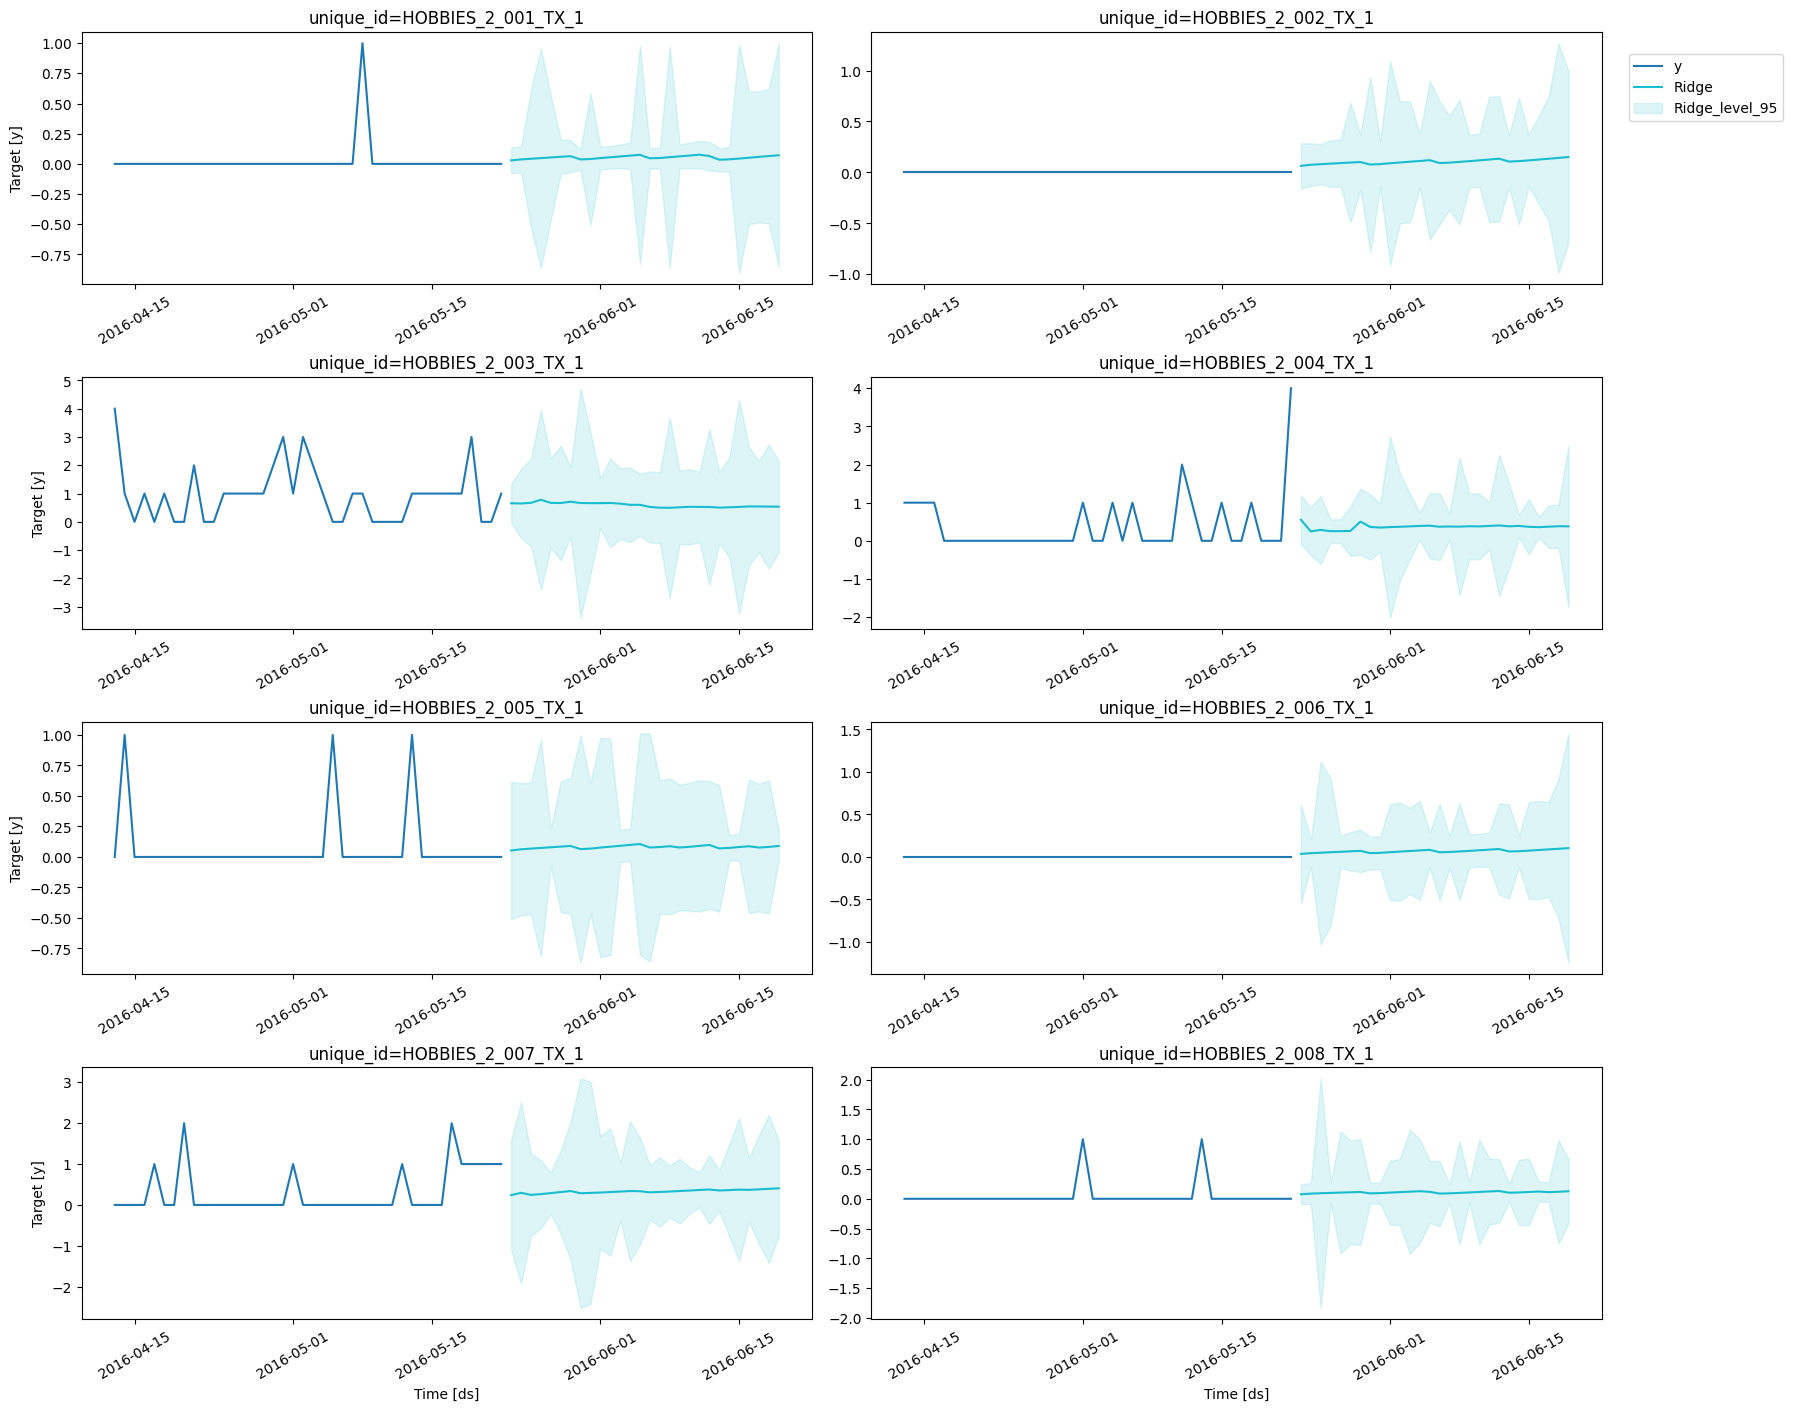

In [64]:
cutoff = train["ds"].max() - pd.Timedelta(days=40)
train_last_40_days = train[train["ds"] >= cutoff]

plot_series(
    train_last_40_days,
    forecasts_final,
    plot_random=False,
    models=["Ridge"],
    level=levels,
    max_insample_length=40
)

### **5.2. Comparação com o melhor modelo da 1ª Fase**

In [65]:
autoets_fase1 = Results_AutoETS[Results_AutoETS["Model"] == "HistoricAverage"]

final_results = pd.concat([autoets_fase1, results_final], ignore_index=True)

final_results

,Model,MSE,MAE,RMSE,RMSSE,MASE
0,HistoricAverage,0.433728,0.342736,0.658580,0.698150,1.049029
1,Ridge,0.438623,0.373352,0.662286,0.702078,1.142737


In [66]:
final_results.to_csv("Results_Fase2.csv", index=False)
files.download("Results_Fase2.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

O Ridge no cenário 1 revelou‑se a melhor configuração entre as doze testadas, apresentando o menor `Total_rank` e desempenho particularmente forte nas métricas quadráticas (MSE, RMSE) e escaladas (RMSSE). Comparando diretamente com o melhor da primeira fase (baseline), verifica‑se que a diferença de desempenho é marginal: o `Ridge_fcst_1` aproxima‑se da baseline (`Historical Average`), mas não a supera de forma clara e consistente. Isto sugere que a série temporal contém sinais que modelos simples capturam bem, pelo que ganhos adicionais com modelos mais complexos são limitados.

